<a href="https://colab.research.google.com/github/ArchishmanS2005/Weighted-Consensus-Clustering-Framework-Using-Hybrid-Bio-Inspired-Optimization-for-Enhanced-Cluster-/blob/main/Weighted_Consensus_Clustering.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd

In [2]:
import numpy as np

In [4]:
import matplotlib.pyplot as plt

In [3]:
import seaborn as sns

In [5]:
from sklearn.datasets import load_iris

In [6]:
iris = load_iris()

In [7]:
df = pd.DataFrame(iris.data, columns=iris.feature_names)

In [8]:
print(df.head())

   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
0                5.1               3.5                1.4               0.2
1                4.9               3.0                1.4               0.2
2                4.7               3.2                1.3               0.2
3                4.6               3.1                1.5               0.2
4                5.0               3.6                1.4               0.2


In [9]:
print(df.isnull().sum())

sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
dtype: int64


In [10]:
print(df.duplicated().sum())

1


In [11]:
df = df.drop_duplicates().reset_index(drop=True)

In [12]:
Q1, Q3 = df.quantile(0.25), df.quantile(0.75)
IQR = Q3 - Q1
print(((df < Q1 - 1.5*IQR) | (df > Q3 + 1.5*IQR)).sum())

sepal length (cm)    0
sepal width (cm)     4
petal length (cm)    0
petal width (cm)     0
dtype: int64


In [13]:
df = df[~((df < Q1 - 1.5*IQR) | (df > Q3 + 1.5*IQR)).any(axis=1)].reset_index(drop=True)

In [14]:
print(df.shape)

(145, 4)


In [15]:
from sklearn.preprocessing import StandardScaler

In [16]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df)

In [17]:
X = pd.DataFrame(X_scaled, columns=df.columns)
print(X.head())

   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
0          -0.907877          1.152206          -1.366548         -1.341462
1          -1.147662         -0.107748          -1.366548         -1.341462
2          -1.387447          0.396234          -1.423536         -1.341462
3          -1.507340          0.144243          -1.309559         -1.341462
4          -1.027769          1.404196          -1.366548         -1.341462


In [18]:
print(df.dtypes)

sepal length (cm)    float64
sepal width (cm)     float64
petal length (cm)    float64
petal width (cm)     float64
dtype: object


In [19]:
print(df.select_dtypes(include='number').shape[1] == df.shape[1])

True


In [20]:
print((np.abs(X) > 3).sum())

sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
dtype: int64


In [21]:
print(X.describe().round(2))

       sepal length (cm)  sepal width (cm)  petal length (cm)  \
count             145.00            145.00             145.00   
mean                0.00             -0.00              -0.00   
std                 1.00              1.00               1.00   
min                -1.87             -2.12              -1.59   
25%                -0.91             -0.61              -1.25   
50%                -0.07             -0.11               0.34   
75%                 0.65              0.65               0.74   
max                 2.45              2.41               1.77   

       petal width (cm)  
count            145.00  
mean              -0.00  
std                1.00  
min               -1.47  
25%               -1.21  
50%                0.11  
75%                0.77  
max                1.70  


In [22]:
from sklearn.cluster import KMeans

In [23]:
wcss = [KMeans(n_clusters=k, random_state=42, n_init=10).fit(X).inertia_ for k in range(1, 11)]

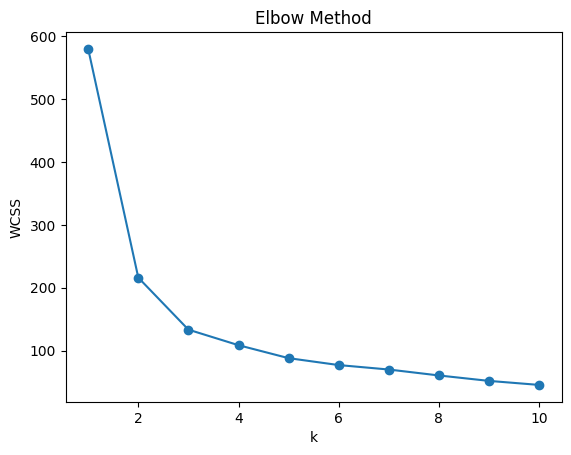

In [24]:
plt.plot(range(1, 11), wcss, marker='o')
plt.xlabel('k'); plt.ylabel('WCSS'); plt.title('Elbow Method')
plt.show()

In [30]:
from sklearn.cluster import DBSCAN
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score

best = None
for min_s in [3, 4, 5, 6, 8, 10]:
    for eps in np.arange(0.2, 1.5, 0.01):
        lb = DBSCAN(eps=eps, min_samples=min_s).fit_predict(X)
        n_cl = len(set(lb)) - (1 if -1 in lb else 0)
        noise = (lb == -1).sum()
        if n_cl == 3 and (best is None or noise < best[3]):
            best = (eps, min_s, lb, noise)

eps, min_s, db_labels, noise = best
print("eps:", round(eps, 2), "| min_samples:", min_s, "| noise points:", noise)

mask = db_labels != -1   # metrics on non-noise points only
Xc, lc = X.values[mask], db_labels[mask]
centers = np.array([Xc[lc == i].mean(axis=0) for i in range(3)])

sse = sum(np.sum((Xc[lc == i] - c)**2) for i, c in enumerate(centers))
cd = [np.sum((centers[i] - centers[j])**2) for i in range(3) for j in range(i+1, 3)]
xb_db = sse / (len(Xc) * min(cd))

print("Silhouette:", silhouette_score(Xc, lc))
print("Davies-Bouldin:", davies_bouldin_score(Xc, lc))
print("Calinski-Harabasz:", calinski_harabasz_score(Xc, lc))
print("Xie-Beni:", xb_db)

eps: 0.95 | min_samples: 3 | noise points: 1
Silhouette: 0.49456489607902426
Davies-Bouldin: 0.5561870235600704
Calinski-Harabasz: 149.89497820058182
Xie-Beni: 0.14262307973522179


In [40]:

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score
from scipy.spatial.distance import pdist, squareform

def calculate_indices(X, labels):
    distances = squareform(pdist(X.values))
    i, j = np.triu_indices(X.shape[0], k=1)
    pair_distances = distances[i, j]

    same = labels[i] == labels[j]
    within = pair_distances[same]
    between = pair_distances[~same]

    m = len(within)
    sorted_distances = np.sort(pair_distances)

    c_index = (np.sum(within) - np.sum(sorted_distances[:m])) / (np.sum(sorted_distances[-m:]) - np.sum(sorted_distances[:m]))
    mcclain_rao = np.mean(between) / np.mean(within)

    return c_index, mcclain_rao


# K-Means
km = KMeans(n_clusters=3, random_state=42, n_init=10)
km_labels = km.fit_predict(X)
centers = km.cluster_centers_

# Xie-Beni (hard memberships, m=2)
sse = sum(np.sum((X.values[km_labels == i] - c)**2) for i, c in enumerate(centers))
cd = [np.sum((centers[i] - centers[j])**2) for i in range(3) for j in range(i+1, 3)]
xb_km = sse / (X.shape[0] * min(cd))

c_km, mr_km = calculate_indices(X, km_labels)

print("Silhouette:", silhouette_score(X, km_labels))
print("DBI:", davies_bouldin_score(X, km_labels))
print("XB:", xb_km)
print("C-Index:", c_km)
print("McClain-Rao:", mr_km)


# Fuzzy C-Means
!pip install scikit-fuzzy -q
import skfuzzy as fuzz
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score

m = 2
cntr, u, _, _, _, _, fpc = fuzz.cmeans(X.T.values, c=3, m=m, error=0.005, maxiter=1000, seed=42)
fcm_labels = np.argmax(u, axis=0)

# Xie-Beni (fuzzy)
d2 = np.array([np.sum((X.values - c)**2, axis=1) for c in cntr])
num = np.sum((u**m) * d2)
cd = [np.sum((cntr[i] - cntr[j])**2) for i in range(3) for j in range(i+1, 3)]
xb = num / (X.shape[0] * min(cd))

c_fcm, mr_fcm = calculate_indices(X, fcm_labels)

print("Silhouette:", silhouette_score(X, fcm_labels))
print("DBI:", davies_bouldin_score(X, fcm_labels))
print("XB:", xb)
print("C-Index:", c_fcm)
print("McClain-Rao:", mr_fcm)


# Gaussian Mixture Model
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score

gmm = GaussianMixture(n_components=3, random_state=42, n_init=10)
gmm_labels = gmm.fit_predict(X)
u = gmm.predict_proba(X).T   # soft memberships (3 x n)
cntr = gmm.means_

# Xie-Beni (soft, m=2)
d2 = np.array([np.sum((X.values - c)**2, axis=1) for c in cntr])
cd = [np.sum((cntr[i] - cntr[j])**2) for i in range(3) for j in range(i+1, 3)]
xb_gmm = np.sum((u**2) * d2) / (X.shape[0] * min(cd))

c_gmm, mr_gmm = calculate_indices(X, gmm_labels)

print("Silhouette:", silhouette_score(X, gmm_labels))
print("DBI:", davies_bouldin_score(X, gmm_labels))
print("XB:", xb_gmm)
print("C-Index:", c_gmm)
print("McClain-Rao:", mr_gmm)


# Agglomerative Clustering
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score

agg = AgglomerativeClustering(n_clusters=3, linkage='ward')
agg_labels = agg.fit_predict(X)
centers = np.array([X.values[agg_labels == i].mean(axis=0) for i in range(3)])

# Xie-Beni (hard memberships, m=2)
sse = sum(np.sum((X.values[agg_labels == i] - c)**2) for i, c in enumerate(centers))
cd = [np.sum((centers[i] - centers[j])**2) for i in range(3) for j in range(i+1, 3)]
xb_agg = sse / (X.shape[0] * min(cd))

c_agg, mr_agg = calculate_indices(X, agg_labels)

print("Silhouette:", silhouette_score(X, agg_labels))
print("DBI:", davies_bouldin_score(X, agg_labels))
print("XB:", xb_agg)
print("C-Index:", c_agg)
print("McClain-Rao:", mr_agg)


# Spectral Clustering
from sklearn.cluster import SpectralClustering
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score

sc = SpectralClustering(n_clusters=3, affinity='nearest_neighbors', n_neighbors=10, random_state=42)    #the nearest-neighbors affinity
sc_labels = sc.fit_predict(X)
centers = np.array([X.values[sc_labels == i].mean(axis=0) for i in range(3)])

# Xie-Beni (hard memberships, m=2)
sse = sum(np.sum((X.values[sc_labels == i] - c)**2) for i, c in enumerate(centers))
cd = [np.sum((centers[i] - centers[j])**2) for i in range(3) for j in range(i+1, 3)]
xb_sc = sse / (X.shape[0] * min(cd))

c_sc, mr_sc = calculate_indices(X, sc_labels)

print("Silhouette:", silhouette_score(X, sc_labels))
print("DBI:", davies_bouldin_score(X, sc_labels))
print("XB:", xb_sc)
print("C-Index:", c_sc)
print("McClain-Rao:", mr_sc)


Silhouette: 0.4649687421839816
DBI: 0.8328740580435344
XB: 0.27056771258194184
C-Index: 0.06455234891195277
McClain-Rao: 2.5706224896511634
Silhouette: 0.4612950687324035
DBI: 0.8358187339872544
XB: 0.2144934275276337
C-Index: 0.06569864732116665
McClain-Rao: 2.56386518999349
Silhouette: 0.3716774942557293
DBI: 1.1004224994064689
XB: 0.5480565635063981
C-Index: 0.10290873003995324
McClain-Rao: 2.305415278236082
Silhouette: 0.4330647337630394
DBI: 0.8096718217207931
XB: 0.2864384523259395
C-Index: 0.07259361571546893
McClain-Rao: 2.4518872459489405
Silhouette: 0.3784248288976022
DBI: 0.9216008020410958
XB: 0.23931157626298483
C-Index: 0.12739228608695297
McClain-Rao: 2.1338658204539827


In [41]:

from sklearn.cluster import DBSCAN
from sklearn.metrics import silhouette_score, davies_bouldin_score
from scipy.spatial.distance import pdist, squareform

best = None
for min_s in [3, 4, 5, 6, 8, 10]:
    for eps in np.arange(0.2, 1.5, 0.01):
        lb = DBSCAN(eps=eps, min_samples=min_s).fit_predict(X)
        n_cl = len(set(lb)) - (1 if -1 in lb else 0)
        noise = (lb == -1).sum()
        if n_cl == 3 and (best is None or noise < best[3]):
            best = (eps, min_s, lb, noise)

eps, min_s, db_labels, noise = best
print("eps:", round(eps, 2), "| min_samples:", min_s, "| noise points:", noise)

mask = db_labels != -1   # metrics on non-noise points only
Xc, lc = X.values[mask], db_labels[mask]
centers = np.array([Xc[lc == i].mean(axis=0) for i in range(3)])

sse = sum(np.sum((Xc[lc == i] - c)**2) for i, c in enumerate(centers))
cd = [np.sum((centers[i] - centers[j])**2) for i in range(3) for j in range(i+1, 3)]
xb_db = sse / (len(Xc) * min(cd))

distances = squareform(pdist(Xc))
i, j = np.triu_indices(len(Xc), k=1)
pair_distances = distances[i, j]

same = lc[i] == lc[j]
within = pair_distances[same]
between = pair_distances[~same]

m = len(within)
sorted_distances = np.sort(pair_distances)

c_db = (np.sum(within) - np.sum(sorted_distances[:m])) / (np.sum(sorted_distances[-m:]) - np.sum(sorted_distances[:m]))
mr_db = np.mean(between) / np.mean(within)

print("Silhouette:", silhouette_score(Xc, lc))
print("DBI:", davies_bouldin_score(Xc, lc))
print("XB:", xb_db)
print("C-Index:", c_db)
print("McClain-Rao:", mr_db)


eps: 0.95 | min_samples: 3 | noise points: 1
Silhouette: 0.49456489607902426
DBI: 0.5561870235600704
XB: 0.14262307973522179
C-Index: 0.030925371047306333
McClain-Rao: 2.4124929374132074


In [54]:

# ===== MAIN CELL: shared data, 5 metrics, fast5, engine gapso (put between Cell 29 and Cell 30) =====
from scipy.spatial.distance import pdist, squareform
from sklearn.metrics import (silhouette_score, silhouette_samples, davies_bouldin_score,
                             adjusted_rand_score, normalized_mutual_info_score)

Xv = X.values

# true species for the cleaned 145 rows (evaluation only, never used in fitting)
d0 = pd.DataFrame(iris.data, columns=iris.feature_names)
keep_ = ~d0.duplicated().values
d1 = d0[keep_].reset_index(drop=True); y1 = iris.target[keep_]
om = ~((d1 < Q1 - 1.5*IQR) | (d1 > Q3 + 1.5*IQR)).any(axis=1).values
y = y1[om]
print("y length (must be 145):", len(y))

# FCM centers (same settings as Cell 25)
cn = fuzz.cmeans(Xv.T, c=3, m=2, error=0.005, maxiter=1000, seed=42)[0]

def xie_beni_hard(Xs, lb):
    ids = np.unique(lb); cs_ = np.array([Xs[lb == i].mean(0) for i in ids])
    sse = sum(np.sum((Xs[lb == i] - c)**2) for i, c in zip(ids, cs_))
    d_ = [np.sum((cs_[i] - cs_[j])**2) for i in range(len(cs_)) for j in range(i+1, len(cs_))]
    return sse / (len(Xs) * min(d_))

def all5(lb):                                     # 5 metrics, DBSCAN noise dropped
    m = lb != -1; Xs, ls = Xv[m], lb[m]; ids = np.unique(ls)
    Dm = squareform(pdist(Xs)); iu = np.triu_indices(len(ls), 1)
    dv_, sv = Dm[iu], (ls[:, None] == ls[None, :])[iu]
    dw, db = dv_[sv], dv_[~sv]; srt_ = np.sort(dv_); nw = len(dw)
    cidx = (dw.sum() - srt_[:nw].sum()) / (srt_[-nw:].sum() - srt_[:nw].sum())
    mcr = dw.mean() / db.mean()
    return [silhouette_score(Xs, ls), davies_bouldin_score(Xs, ls),
            xie_beni_hard(Xs, ls), cidx, mcr]

cols = ['Silhouette', 'DBI', 'XB', 'C-Index', 'McClain-Rao']   # 5 metrics
up = ['Silhouette']                                            # higher is better

all_labels = {'KMeans': km_labels, 'FCM': fcm_labels, 'GMM': gmm_labels,
              'Agglomerative': agg_labels, 'Spectral': sc_labels, 'DBSCAN': db_labels}
M8 = pd.DataFrame({n: all5(l) for n, l in all_labels.items()}, index=cols).T
print(M8.round(4))

# ---- fast version of the 5 metrics ----
n = len(Xv); Dfull = squareform(pdist(Xv))
dv = Dfull[np.triu_indices(n, 1)]; srt = np.sort(dv)
cs = np.concatenate([[0], np.cumsum(srt)]); tot = cs[-1]; NP = len(srt)

def fast5(lb):
    ids = np.unique(lb)
    if len(ids) != 3: return None
    own = np.searchsorted(ids, lb); oh = np.eye(3)[own]; cnt = oh.sum(0)
    if cnt.min() < 2: return None
    S = Dfull @ oh; r = np.arange(n)
    a = S[r, own] / (cnt[own] - 1)
    Sm = S / cnt; Sm[r, own] = np.inf; b = Sm.min(1)
    s = (b - a) / np.maximum(a, b)
    cen = np.array([Xv[own == i].mean(0) for i in range(3)])
    sc_ = np.array([np.linalg.norm(Xv[own == i] - cen[i], axis=1).mean() for i in range(3)])
    cd = squareform(pdist(cen)); np.fill_diagonal(cd, np.inf)
    dbi = ((sc_[:, None] + sc_[None, :]) / cd).max(1).mean()
    same = (oh @ oh.T) > 0
    wsum = (Dfull * same).sum() / 2; nw = int((same.sum() - n) / 2)
    cidx = (wsum - cs[nw]) / ((tot - cs[NP - nw]) - cs[nw])
    mcr = (wsum / nw) / ((tot - wsum) / (NP - nw))
    return np.array([s.mean(), dbi, xie_beni_hard(Xv, own), cidx, mcr])

print("Check (must match, 5 values each):\n", np.round(fast5(km_labels), 4), "\n", M8.loc['KMeans'].values.round(4))

sign = np.array([1 if c in up else -1 for c in cols])
def rel(v, bv): return sign * (np.asarray(v) - bv) / np.abs(bv)
def stat(v, bv): return ['Better' if x > 1e-4 else 'Worse' if x < -1e-4 else 'Equal' for x in rel(v, bv)]
def all_better(v, bv): return all(s == 'Better' for s in stat(v, bv))

def gapso(evalf, lo, hi, pop, stop, iters=100, patience=40, seed=1):
    rng = np.random.default_rng(seed); P_, dim = pop.shape; sd = (hi - lo) / 10
    res = [evalf(p) for p in pop]; f = np.array([r[0] for r in res])
    i = f.argmin(); gb, gbf, gv, best_it = pop[i].copy(), f[i], res[i][1], 0
    for it in range(1, iters + 1):
        if it <= 30:                                           # GA phase
            elite = pop[np.argsort(f)[:2]].copy()
            idx = [min(rng.choice(P_, 3, replace=False), key=lambda j: f[j]) for _ in range(P_)]
            par = pop[idx]; a = rng.random((P_, 1))
            ch = a * par + (1 - a) * par[::-1]
            ch += (rng.random((P_, dim)) < 0.2) * rng.normal(0, 1, (P_, dim)) * sd
            pop = np.clip(ch, lo, hi); pop[:2] = elite
            res = [evalf(p) for p in pop]; f = np.array([r[0] for r in res]); i = f.argmin()
            if f[i] < gbf - 1e-12: gb, gbf, gv, best_it = pop[i].copy(), f[i], res[i][1], it
        else:                                                  # PSO phase
            if it == 31: pos, vel = pop.copy(), np.zeros_like(pop); pb, pbf = pos.copy(), f.copy()
            r1, r2 = rng.random((P_, dim)), rng.random((P_, dim))
            vel = 0.7 * vel + 1.5 * r1 * (pb - pos) + 1.5 * r2 * (gb - pos)
            pos = np.clip(pos + vel, lo, hi)
            res = [evalf(p) for p in pos]; fp = np.array([r[0] for r in res])
            m = fp < pbf; pb[m], pbf[m] = pos[m], fp[m]; i = fp.argmin()
            if fp[i] < gbf - 1e-12: gb, gbf, gv, best_it = pos[i].copy(), fp[i], res[i][1], it
        if gv is not None and stop(gv): return gb, gv, it, True, best_it
        if it > 30 and it - best_it > patience: return gb, gv, it, False, best_it
    return gb, gv, iters, False, best_it
print("Main cell ready")


y length (must be 145): 145
               Silhouette     DBI      XB  C-Index  McClain-Rao
KMeans             0.4650  0.8329  0.2706   0.0646       0.3890
FCM                0.4613  0.8358  0.2740   0.0657       0.3900
GMM                0.3717  1.1004  0.5317   0.1029       0.4338
Agglomerative      0.4331  0.8097  0.2864   0.0726       0.4078
Spectral           0.3784  0.9216  0.2393   0.1274       0.4686
DBSCAN             0.4946  0.5562  0.1426   0.0309       0.4145
Check (must match, 5 values each):
 [0.465  0.8329 0.2706 0.0646 0.389 ] 
 [0.465  0.8329 0.2706 0.0646 0.389 ]
Main cell ready


In [55]:

from sklearn.cluster import DBSCAN
from sklearn.mixture import GaussianMixture
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score, confusion_matrix
from scipy.optimize import linear_sum_assignment

LAMBDA = 70                                       # penalty weight for any metric that gets worse
def fitness(v, bv):                               # lower is better
    r = np.clip(rel(v, bv), -1, 1); return -r.sum() + LAMBDA * np.clip(-r, 0, None).sum()

def acc_(yt, yp):                                 # accuracy after best cluster-to-class matching
    cm = confusion_matrix(yt, yp); r, c = linear_sum_assignment(-cm); return cm[r, c].sum() / len(yt)

P, win = 20, 0.15
TAU, MU = 0.8, 50                                 # min agreement with base labels, penalty weight
agree_pen = lambda b, l: MU * max(0.0, TAU - adjusted_rand_score(b[(b != -1) & (l != -1)], l[(b != -1) & (l != -1)]))
span = (Xv.max(0) - Xv.min(0)).mean()
km_c = km.cluster_centers_.ravel()
gmm_c = GaussianMixture(3, random_state=42, n_init=10).fit(Xv).means_.ravel()
seeds = {'KMeans': km_c, 'FCM': cn.ravel(), 'GMM': gmm_c,
         'Agglomerative': np.array([Xv[agg_labels == i].mean(0) for i in range(3)]).ravel(),
         'Spectral': np.array([Xv[sc_labels == i].mean(0) for i in range(3)]).ravel()}

def mk_eval(bv, base_lab):                        # centroid-based algorithms
    def ev(p):
        lb = ((Xv[:, None, :] - p.reshape(3, 4)[None])**2).sum(2).argmin(1)
        v = fast5(lb)
        return (99.0, None) if v is None else (fitness(v, bv) + agree_pen(base_lab, lb), v)
    return ev

def mk_db_eval(bv):                               # DBSCAN: searches eps and min_samples
    def ev(p):
        lb = DBSCAN(eps=p[0], min_samples=int(round(p[1]))).fit_predict(Xv)
        if len(set(lb)) - (1 if -1 in lb else 0) != 3 or (lb == -1).sum() > 7: return 99.0, None
        v = all5(lb)
        return fitness(v, bv) + agree_pen(all_labels['DBSCAN'], lb), np.array(v)
    return ev
print("Cell 1 ready, LAMBDA =", LAMBDA)


Cell 1 ready, LAMBDA = 70


In [56]:

def psosa(evalf, lo, hi, pop, stop, iters=100, pso_its=50, patience=40, seed=1, T0=0.05, cool=0.9):
    rng = np.random.default_rng(seed); P_, dim = pop.shape; sd = (hi - lo) / 10
    res = [evalf(p) for p in pop]; f = np.array([r[0] for r in res]); i = f.argmin()
    gb, gbf, gv, best_it = pop[i].copy(), f[i], res[i][1], 0
    pos, vel = pop.copy(), np.zeros_like(pop); pb, pbf = pos.copy(), f.copy()
    for it in range(1, iters + 1):
        if it <= pso_its:                                      # PSO phase
            r1, r2 = rng.random((P_, dim)), rng.random((P_, dim))
            vel = 0.7 * vel + 1.5 * r1 * (pb - pos) + 1.5 * r2 * (gb - pos)
            pos = np.clip(pos + vel, lo, hi)
            res = [evalf(p) for p in pos]; fp = np.array([r[0] for r in res])
            m = fp < pbf; pb[m], pbf[m] = pos[m], fp[m]; i = fp.argmin()
            if fp[i] < gbf - 1e-12: gb, gbf, gv, best_it = pos[i].copy(), fp[i], res[i][1], it
        else:                                                  # SA phase
            if it == pso_its + 1: cur, curf, T = gb.copy(), gbf, T0
            step = sd * (0.2 + 0.8 * T / T0)
            cand = np.clip(cur + rng.normal(0, 1, (P_, dim)) * step, lo, hi)
            res = [evalf(p) for p in cand]; fc = np.array([r[0] for r in res]); j = fc.argmin()
            dlt = fc[j] - curf
            if dlt < 0 or rng.random() < np.exp(-dlt / T): cur, curf = cand[j].copy(), fc[j]
            if fc[j] < gbf - 1e-12: gb, gbf, gv, best_it = cand[j].copy(), fc[j], res[j][1], it
            T *= cool
        if gv is not None and stop(gv): return gb, gv, it, True, best_it
        if it > pso_its and it - best_it > patience: return gb, gv, it, False, best_it
    return gb, gv, iters, False, best_it

def gagwo(evalf, lo, hi, pop, stop, iters=100, ga_its=30, patience=40, seed=1):
    rng = np.random.default_rng(seed); P_, dim = pop.shape; sd = (hi - lo) / 10
    res = [evalf(p) for p in pop]; f = np.array([r[0] for r in res]); i = f.argmin()
    gb, gbf, gv, best_it = pop[i].copy(), f[i], res[i][1], 0
    for it in range(1, iters + 1):
        if it <= ga_its:                                       # GA phase
            elite = pop[np.argsort(f)[:2]].copy()
            idx = [min(rng.choice(P_, 3, replace=False), key=lambda j: f[j]) for _ in range(P_)]
            par = pop[idx]; a_ = rng.random((P_, 1))
            ch = a_ * par + (1 - a_) * par[::-1]
            ch += (rng.random((P_, dim)) < 0.2) * rng.normal(0, 1, (P_, dim)) * sd
            pop = np.clip(ch, lo, hi); pop[:2] = elite
        else:                                                  # GWO phase
            o = np.argsort(f)[:3]; Xa, Xb, Xd = pop[o[0]], pop[o[1]], pop[o[2]]
            a = 2 * (1 - (it - ga_its) / (iters - ga_its))
            new = np.zeros_like(pop)
            for Ld in (Xa, Xb, Xd):
                A = 2 * a * rng.random((P_, dim)) - a; Cc = 2 * rng.random((P_, dim))
                new += Ld - A * np.abs(Cc * Ld - pop)
            pop = np.clip(new / 3, lo, hi); pop[0] = gb
        res = [evalf(p) for p in pop]; f = np.array([r[0] for r in res]); i = f.argmin()
        if f[i] < gbf - 1e-12: gb, gbf, gv, best_it = pop[i].copy(), f[i], res[i][1], it
        if gv is not None and stop(gv): return gb, gv, it, True, best_it
        if it > ga_its and it - best_it > patience: return gb, gv, it, False, best_it
    return gb, gv, iters, False, best_it

def acopso(evalf, lo, hi, pop, stop, iters=100, aco_its=40, patience=40, seed=1, q=0.3, xi=0.85):
    rng = np.random.default_rng(seed); P_, dim = pop.shape
    res = [evalf(p) for p in pop]; f = np.array([r[0] for r in res]); i = f.argmin()
    gb, gbf, gv, best_it = pop[i].copy(), f[i], res[i][1], 0
    for it in range(1, iters + 1):
        if it <= aco_its:                                      # ACO phase (ACOR)
            o = np.argsort(f); pop, f = pop[o], f[o]
            w = np.exp(-(np.arange(P_)) ** 2 / (2 * (q * P_) ** 2)); w /= w.sum()
            sig = xi * np.abs(pop[None, :, :] - pop[:, None, :]).sum(1) / (P_ - 1)
            g = rng.choice(P_, P_, p=w)
            ants = np.clip(rng.normal(pop[g], sig[g] + 1e-12), lo, hi)
            res = [evalf(p) for p in ants]; fa = np.array([r[0] for r in res])
            allp = np.vstack([pop, ants]); allf = np.concatenate([f, fa])
            keep = np.argsort(allf)[:P_]; pop, f = allp[keep], allf[keep]
            i = int(np.argmin(fa))
            if fa[i] < gbf - 1e-12: gb, gbf, gv, best_it = ants[i].copy(), fa[i], res[i][1], it
        else:                                                  # PSO phase
            if it == aco_its + 1: pos, vel = pop.copy(), np.zeros_like(pop); pb, pbf = pos.copy(), f.copy()
            r1, r2 = rng.random((P_, dim)), rng.random((P_, dim))
            vel = 0.7 * vel + 1.5 * r1 * (pb - pos) + 1.5 * r2 * (gb - pos)
            pos = np.clip(pos + vel, lo, hi)
            res = [evalf(p) for p in pos]; fp = np.array([r[0] for r in res])
            m = fp < pbf; pb[m], pbf[m] = pos[m], fp[m]; i = fp.argmin()
            if fp[i] < gbf - 1e-12: gb, gbf, gv, best_it = pos[i].copy(), fp[i], res[i][1], it
        if gv is not None and stop(gv): return gb, gv, it, True, best_it
        if it > aco_its and it - best_it > patience: return gb, gv, it, False, best_it
    return gb, gv, iters, False, best_it

print("Engines ready")


Engines ready


In [57]:

NOSTOP = lambda v: False
ITER = {}                                          # stores best iteration for every hybrid

def run_block(engine, tag):
    hl, ot = {}, {}
    for name, sc_ in seeds.items():
        bv = M8.loc[name].values
        cents = [sc_] if name == 'KMeans' else [sc_, km_c]
        lo = np.min(cents, 0) - win * span; hi = np.max(cents, 0) + win * span
        rng = np.random.default_rng(1); m_ = P // len(cents)
        pop = np.vstack([c + rng.normal(0, 0.02 * span, (m_, 12)) for c in cents])
        for j, c in enumerate(cents): pop[j * m_] = c
        gb, gv, it, _, bit = engine(mk_eval(bv, all_labels[name]), lo, hi, pop, NOSTOP)
        hl[name] = ((Xv[:, None, :] - gb.reshape(3, 4)[None])**2).sum(2).argmin(1)
        ot[name] = (bv, gv, stat(gv, bv)); ITER[f'{tag}+{name}'] = (bit, it)
    bv = M8.loc['DBSCAN'].values                   # DBSCAN: eps, min_samples
    lo, hi = np.array([0.3, 2.0]), np.array([1.5, 12.0]); rng = np.random.default_rng(1)
    pop = np.column_stack([rng.uniform(lo[0], hi[0], P), rng.uniform(lo[1], hi[1], P)])
    pop[:5, 0] = best[0] + rng.normal(0, 0.05, 5); pop[:5, 1] = best[1]; pop[0] = [best[0], best[1]]
    gb, gv, it, _, bit = engine(mk_db_eval(bv), lo, hi, pop, NOSTOP)
    hl['DBSCAN'] = DBSCAN(eps=gb[0], min_samples=int(round(gb[1]))).fit_predict(Xv)
    ot['DBSCAN'] = (bv, gv, stat(gv, bv)); ITER[f'{tag}+DBSCAN'] = (bit, it)
    print(f"\n===== {tag}: Better / Equal / Worse | best iteration | iterations run =====")
    for n_, (_, _, s) in ot.items():
        b_, r_ = ITER[f'{tag}+{n_}']
        print(f"{n_:14s} {s.count('Better')} / {s.count('Equal')} / {s.count('Worse')}  | best at iter {b_:3d} | ran {r_:3d} | sizes {np.bincount(hl[n_][hl[n_] != -1])}")
    return hl, ot

hyb_labels, out    = run_block(gapso,  'GA+PSO')
hyb_ps,     out_ps = run_block(psosa,  'PSO+SA')
hyb_gg,     out_gg = run_block(gagwo,  'GA+GWO')
hyb_ap,     out_ap = run_block(acopso, 'ACO+PSO')

# one summary table of all 24 hybrids
IT = pd.DataFrame(ITER, index=['Best_iter', 'Iterations_run']).T
print("\n===== Best iteration, all 24 hybrids ====="); print(IT)
IT.to_csv('best_iterations.csv')



===== GA+PSO: Better / Equal / Worse | best iteration | iterations run =====
KMeans         5 / 0 / 0  | best at iter   3 | ran  44 | sizes [58 47 40]
FCM            5 / 0 / 0  | best at iter   6 | ran  47 | sizes [58 47 40]
GMM            5 / 0 / 0  | best at iter  26 | ran  67 | sizes [46 44 55]
Agglomerative  5 / 0 / 0  | best at iter  26 | ran  67 | sizes [77 46 22]
Spectral       5 / 0 / 0  | best at iter   3 | ran  44 | sizes [41 33 71]
DBSCAN         5 / 0 / 0  | best at iter   7 | ran  48 | sizes [46 94  2]

===== PSO+SA: Better / Equal / Worse | best iteration | iterations run =====
KMeans         5 / 0 / 0  | best at iter   7 | ran  51 | sizes [58 47 40]
FCM            5 / 0 / 0  | best at iter   3 | ran  51 | sizes [47 57 41]
GMM            5 / 0 / 0  | best at iter  22 | ran  63 | sizes [46 42 57]
Agglomerative  5 / 0 / 0  | best at iter   4 | ran  51 | sizes [77 46 22]
Spectral       5 / 0 / 0  | best at iter   5 | ran  51 | sizes [41 33 71]
DBSCAN         5 / 0 / 0  | be

In [58]:

pd.set_option('display.width', 250)
for tag, o in [('GA+PSO', out), ('PSO+SA', out_ps), ('GA+GWO', out_gg), ('ACO+PSO', out_ap)]:
    for n_, (bv, gv, st) in o.items():
        idx = cols if len(cols) == len(bv) else [f'metric{i+1}' for i in range(len(bv))]
        print(f"\n===== {tag}+{n_} =====")
        print(pd.DataFrame({'Base': bv, 'Hybrid': gv, 'Result': st}, index=idx).round(4))



===== GA+PSO+KMeans =====
               Base  Hybrid  Result
Silhouette   0.4650  0.4677  Better
DBI          0.8329  0.8304  Better
XB           0.2706  0.2671  Better
C-Index      0.0646  0.0625  Better
McClain-Rao  0.3890  0.3882  Better

===== GA+PSO+FCM =====
               Base  Hybrid  Result
Silhouette   0.4613  0.4677  Better
DBI          0.8358  0.8304  Better
XB           0.2740  0.2671  Better
C-Index      0.0657  0.0625  Better
McClain-Rao  0.3900  0.3882  Better

===== GA+PSO+GMM =====
               Base  Hybrid  Result
Silhouette   0.3717  0.4190  Better
DBI          1.1004  0.9156  Better
XB           0.5317  0.3274  Better
C-Index      0.1029  0.0837  Better
McClain-Rao  0.4338  0.4115  Better

===== GA+PSO+Agglomerative =====
               Base  Hybrid  Result
Silhouette   0.4331  0.4555  Better
DBI          0.8097  0.7504  Better
XB           0.2864  0.2428  Better
C-Index      0.0726  0.0653  Better
McClain-Rao  0.4078  0.4075  Better

===== GA+PSO+Spectral ====

In [66]:

# ===== IRIS FINAL: weighted consensus (5 stages, all 6 vote) + index check + final 35-method tables =====
MODE = 'improved'            # 'iris' = plain quality weights | 'improved' = quality x cluster-balance
K = 3
MIN_FRAC, MAX_FRAC = 0.05, 0.80

import numpy as np, pandas as pd
from sklearn.cluster import AgglomerativeClustering

pd.set_option('display.width', 300); pd.set_option('display.max_columns', 50); pd.set_option('display.max_rows', 100)

use = ['Silhouette', 'DBI', 'XB', 'C-Index', 'McClain-Rao']
hi_ = ['Silhouette']
up_set = {'Silhouette'}

N_ROWS = len(Xv)
ENG = {'GA+PSO': (hyb_labels, out), 'PSO+SA': (hyb_ps, out_ps), 'GA+GWO': (hyb_gg, out_gg), 'ACO+PSO': (hyb_ap, out_ap)}

def valid(l):
    cnt = np.bincount(l[l != -1], minlength=K)
    return cnt.min() >= MIN_FRAC * N_ROWS and cnt.max() <= MAX_FRAC * N_ROWS

def balance(l):                                      # 1 = equal sizes, near 0 = one giant cluster
    cnt = np.bincount(l[l != -1], minlength=K).astype(float); p = cnt / cnt.sum(); p = p[p > 0]
    return float(-(p * np.log(p)).sum() / np.log(K))

def coassoc(lb):
    A = (lb[:, None] == lb[None, :]).astype(float)
    nz = lb == -1; A[nz, :] = 0; A[:, nz] = 0; A[nz, nz] = 1
    return A

def weighted_consensus(labs, Q):                     # ALL 6 algorithms vote
    names = list(labs); Qv = Q.loc[names, use]
    Nn = (Qv - Qv.min()) / (Qv.max() - Qv.min() + 1e-12)            # 1) weights from quality
    for c in use:
        if c not in hi_: Nn[c] = 1 - Nn[c]
    score = Nn.mean(axis=1) + 0.01
    bal = pd.Series({nm: balance(labs[nm]) for nm in names})
    if MODE == 'improved': score = score * bal
    w = score / score.sum()
    C = sum(w[nm] * coassoc(labs[nm]) for nm in names)               # 2) co-association, 3) weighted sum
    C = np.clip(C, 0, 1); np.fill_diagonal(C, 1)
    D = 1 - C; np.fill_diagonal(D, 0)
    for link in ['average', 'complete']:
        cl = AgglomerativeClustering(n_clusters=K, metric='precomputed', linkage=link).fit_predict(D)
        if valid(cl): break
    return cl, w, bal, link

def stage_table(labs, Q, cl, name):
    rows = {n_: list(Q.loc[n_].values) for n_, l in labs.items()}
    rows[name] = list(all5(cl))
    T = pd.DataFrame(rows, index=cols).T
    allv = dict(labs); allv[name] = cl
    T['Clusters'] = [len(set(l)) - (1 if -1 in l else 0) for l in allv.values()]
    T['Min_Cluster'] = [np.bincount(l[l != -1]).min() for l in allv.values()]
    R = pd.DataFrame({c: T[c].rank(ascending=(c not in up_set)) for c in use})
    T['Avg_Rank'] = R.mean(axis=1); T['Overall_Rank'] = T['Avg_Rank'].rank(method='min').astype(int)
    return T.sort_values('Avg_Rank')

# ---------- 5 weighted consensus stages ----------
CONS, TAB = {}, {}
stages = [('Base', all_labels, M8.loc[list(all_labels.keys()), cols])]
for eng, (hl, ot) in ENG.items():
    stages.append((eng, {n_: hl[n_] for n_ in all_labels}, pd.DataFrame({n_: ot[n_][1] for n_ in all_labels}, index=cols).T))

for tag, labs, Q in stages:
    cl, w, bal, link = weighted_consensus(labs, Q)
    CONS[tag] = cl; TAB[tag] = stage_table(labs, Q, cl, f'{tag} Consensus')
    print(f"\n===== {tag} [{MODE}] | linkage: {link} | sizes: {np.bincount(cl)} =====")
    print("balance:", bal.round(3).to_dict()); print("weights:", w.round(3).to_dict())
    print(TAB[tag].round(4))

# ---------- index check over the 24 hybrids: keep indices that are never worse ----------
cand = cols

def verdict(c, vb, vh):
    r = (vh - vb) / max(abs(vb), 1e-12) * (1 if c in up_set else -1)
    return 'Better' if r > 1e-4 else 'Worse' if r < -1e-4 else 'Equal'

V = {c: [] for c in cand}
for g, (hl, ot) in ENG.items():
    for a, (bv_, gv_, st_) in ot.items():
        for c, s in zip(cols, st_): V[c].append(s)

IDX = pd.DataFrame({c: {x: V[c].count(x) for x in ['Better', 'Equal', 'Worse']} for c in cand}).T
print("\nIndex check over 24 hybrids:\n", IDX)

MAX_WORSE = 0
while True:
    keep = [c for c in cand if IDX.loc[c, 'Worse'] <= MAX_WORSE]
    if len(keep) >= 3: break
    MAX_WORSE += 1

print("Indices used in the final table:", keep, "| allowed Worse:", MAX_WORSE)

# ---------- all 35 methods ----------
all35 = dict(all_labels); all35['Base Consensus'] = CONS['Base']
for g, (hl, ot) in ENG.items():
    for a in all_labels: all35[f'{g}+{a}'] = hl[a]
    all35[f'{g} Consensus'] = CONS[g]

rows = {}
for nm, l in all35.items():
    if nm in all_labels: v = list(M8.loc[nm, cols].values)
    elif nm.endswith('Consensus'): v = list(all5(l))
    else: g, a = nm.rsplit('+', 1); v = list(ENG[g][1][a][1])
    rows[nm] = v

T35 = pd.DataFrame(rows, index=cols).T
T35['Clusters'] = [len(set(l)) - (1 if -1 in l else 0) for l in all35.values()]
T35['Min_Cluster'] = [np.bincount(l[l != -1]).min() for l in all35.values()]
T35['Valid'] = [valid(l) for l in all35.values()]
T35['Type'] = ['Base'] * 6 + ['Base Consensus'] + (['Hybrid'] * 6 + ['Hybrid Consensus']) * 4

def rank_table(T, idx):
    R = pd.DataFrame({c: T[c].rank(ascending=(c not in up_set)) for c in idx})
    o = T.copy(); o['Avg_Rank'] = R.mean(axis=1); o['Overall_Rank'] = o['Avg_Rank'].rank(method='min').astype(int)
    return o.sort_values('Avg_Rank')

tail = ['Avg_Rank', 'Overall_Rank', 'Clusters', 'Min_Cluster', 'Valid', 'Type']
TA = rank_table(T35, use)
TF = rank_table(T35, keep)[keep + tail]                          # FINAL: all 35, selected indices

print("\n===== FINAL TABLE (all 35, selected indices) =====")
print(TF.round(4))

TA.round(4).to_csv(f'iris_all_35_full_{MODE}.csv')
TF.round(4).to_csv(f'iris_final_35_{MODE}.csv')

print("Saved iris_final_35_%s.csv, iris_all_35_full_%s.csv" % (MODE, MODE))



===== Base [improved] | linkage: average | sizes: [53 47 45] =====
balance: {'KMeans': 0.998, 'FCM': 0.999, 'GMM': 0.997, 'Agglomerative': 0.941, 'Spectral': 0.95, 'DBSCAN': 0.655}
weights: {'KMeans': 0.241, 'FCM': 0.237, 'GMM': 0.049, 'Agglomerative': 0.191, 'Spectral': 0.075, 'DBSCAN': 0.207}
                Silhouette     DBI      XB  C-Index  McClain-Rao  Clusters  Min_Cluster  Avg_Rank  Overall_Rank
DBSCAN              0.4946  0.5562  0.1426   0.0309       0.4145         3            3       1.8             1
KMeans              0.4650  0.8329  0.2706   0.0646       0.3890         3           45       2.7             2
Base Consensus      0.4650  0.8329  0.2706   0.0646       0.3890         3           45       2.7             2
FCM                 0.4613  0.8358  0.2740   0.0657       0.3900         3           47       4.2             4
Agglomerative       0.4331  0.8097  0.2864   0.0726       0.4078         3           28       4.4             5
Spectral            0.3784  0.9

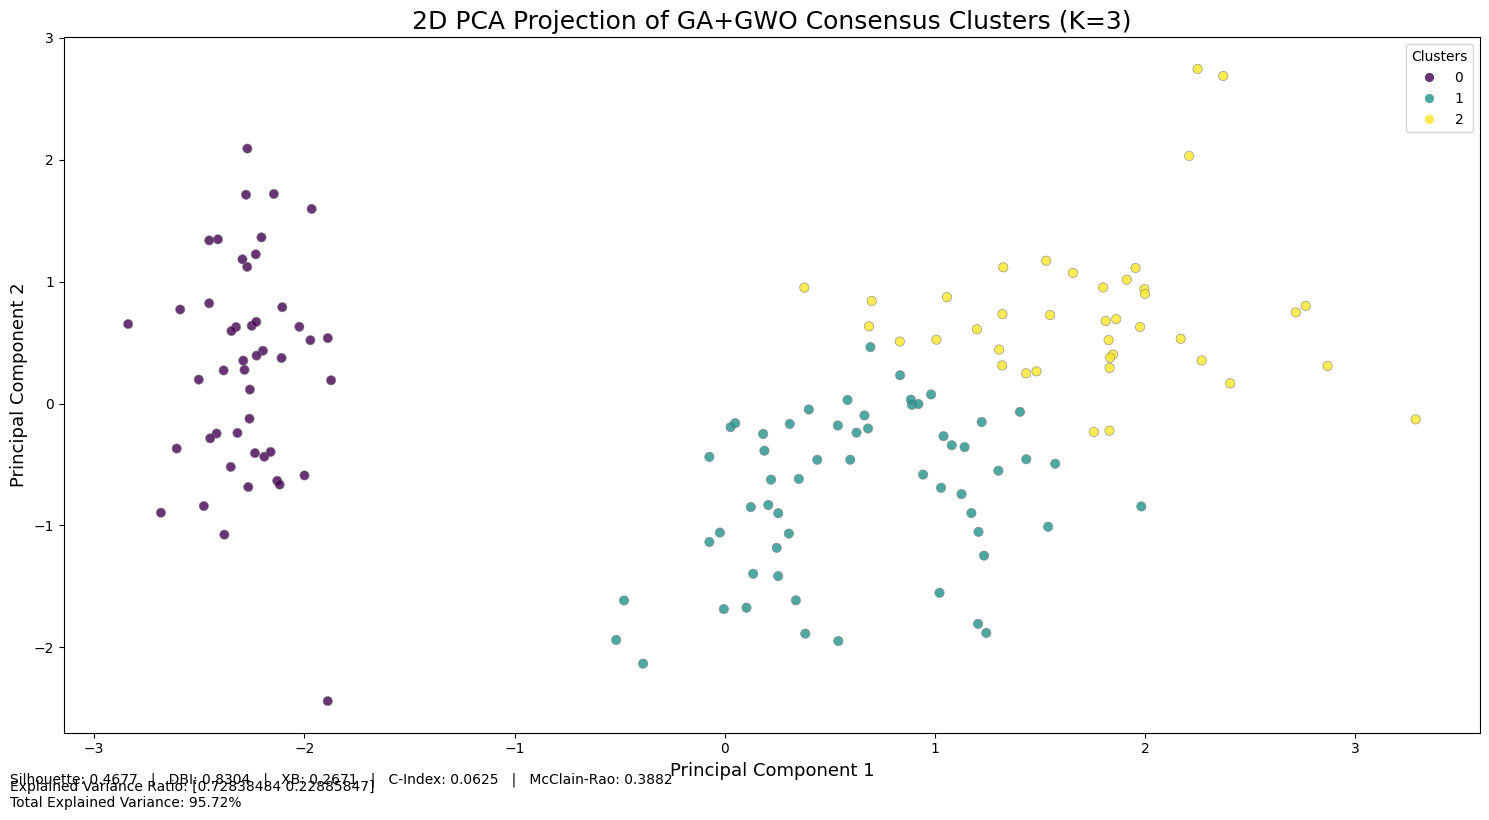

In [63]:

import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

# GA+GWO Consensus labels
labels = CONS['GA+GWO']

# 2D PCA projection
pca = PCA(n_components=2)
X_pca = pca.fit_transform(Xv)

# Plot
plt.figure(figsize=(15, 8))

scatter = plt.scatter(
    X_pca[:, 0], X_pca[:, 1],
    c=labels, cmap='viridis',
    s=45, alpha=0.8,
    edgecolors='gray', linewidths=0.5
)

plt.title('2D PCA Projection of GA+GWO Consensus Clusters (K=3)', fontsize=18)
plt.xlabel('Principal Component 1', fontsize=13)
plt.ylabel('Principal Component 2', fontsize=13)

plt.legend(*scatter.legend_elements(), title="Clusters", loc="upper right")
plt.grid(False)

plt.figtext(
    0.01, 0.015,
    "Silhouette: 0.4677   |   DBI: 0.8304   |   XB: 0.2671   |   C-Index: 0.0625   |   McClain-Rao: 0.3882",
    fontsize=10
)

plt.figtext(
    0.01, -0.015,
    f"Explained Variance Ratio: {np.round(pca.explained_variance_ratio_, 8)}\n"
    f"Total Explained Variance: {pca.explained_variance_ratio_.sum()*100:.2f}%",
    fontsize=10
)

plt.tight_layout()
plt.show()


In [64]:
import getpass

GITHUB_TOKEN = getpass.getpass("Enter your GitHub token: ")
GITHUB_USERNAME = "ArchishmanS2005"

REPO_NAME = "Weighted-Consensus-Clustering-Framework-Using-Hybrid-Bio-Inspired-Optimization-for-Enhanced-Cluster-"

Enter your GitHub token: ··········
